In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import astropy.units as u
import astropy.constants as const
from galpy.orbit import Orbit
from galpy.util import conversion

from galpy.potential import vcirc
from galpy.potential import SCFPotential, scf_compute_coeffs_nbody
from galpy.potential import interpSphericalPotential
from galpy.potential import evaluatePotentials
from galpy.potential import evaluateDensities
from galpy.potential import (PlummerPotential, EinastoPotential,
                             TruncatedNFWPotential, TruncatedHernquistPotential)

In [12]:
def potential_plotter(file, plot_potential=True, plot_density=True):
    """
    Builds a spherical potential from the DM particles in 'file' and plots the potential and density
    
    Parameters:

    file : .hdf5 file
            Data from the  TNG simulation (one halo)
    
    plot_potential : bool
                     Boolean that determines if the potential should be plotted
    
    plot_density : bool
                   Boolean that determines if the density should be plotted        
    
    Returns:

    pot : galpy.potential
          The potential constructed from the data in 'file'

    rplot : astropy Quantity
            Radii (kpc) at which the density was evaluated

    rho : astropy Quantity
          Density (Msun/kpc^3) at those radii
    """
    # galpy's unit scales
    ro, vo = 8.0 * u.kpc, 220.0 * u.km / u.s

    # Open file, get particle positions and masses
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        m = np.full(len(pos), hdr["MassTable"][1])   # all DM particles have equal mass in TNG

    # Get hubble param and divide by it, convention in TNG
    h = hdr.get("HubbleParam", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    M_unit = hdr.get("UnitMass_in_g", 1.989e43) * u.g / h

    # Convert data to more conventional units
    pos = pos * L_unit.to(u.kpc)
    m = m * M_unit.to(u.Msun)

    # Calculate the center of all particles
    center = np.average(pos.value, axis=0, weights=m.value) * u.kpc
    # Calculate all radii w.r.t. center and sort them in increasing r
    r = np.linalg.norm((pos - center).value, axis=1) * u.kpc
    order = np.argsort(r)
    # The mass is the total enclosed mass
    r, M = r[order], np.cumsum(m[order])

    # Make a grid of radii, interpolate between radii in r and assign a mass to each gridpoint.
    # Only start at the 100th particle, starting from the 0th particle includes too much noise
    rgrid_phys = np.geomspace(r[100], r[-1], 200)
    Mgrid_phys = np.interp(rgrid_phys, r, M)

    # Radial force grid in physical units, with G from astropy: F = -G M / r^2  [(km/s)^2 / kpc]
    Fgrid_phys = (-const.G * Mgrid_phys / rgrid_phys**2).to(u.km**2 / u.s**2 / u.kpc)

    # Express rgrid and Fgrid in galpy's unit scales
    rgrid = (rgrid_phys / ro).decompose().value
    Fgrid = (Fgrid_phys / (vo**2 / ro)).decompose().value

    pot = interpSphericalPotential(
        rforce=lambda x: np.interp(x, rgrid, Fgrid),
        rgrid=rgrid, ro=ro.to_value(u.kpc), vo=vo.to_value(u.km / u.s))

    # Get the potentia at the grid points
    Phi = evaluatePotentials(pot, rgrid_phys, 0. * u.kpc, quantity=True)
    Phi = Phi.to(u.km**2 / u.s**2)
    # Shift so the outer edge matches a point mass, Phi = -G M_tot / r (zero at infinity)
    Phi = Phi - Phi[-1] + (-const.G * Mgrid_phys[-1] / rgrid_phys[-1]).to(u.km**2 / u.s**2)

    # Get the density at the grid points
    rho = evaluateDensities(pot, rgrid_phys, 0. * u.kpc, quantity=True)
    rho = rho.to(u.Msun / u.kpc**3)

    if plot_potential:
        plt.semilogx(rgrid_phys.value, Phi.value)
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$\Phi$ [(km/s)$^2$]")
        plt.title("Potential")
        plt.show()

    if plot_density:
        plt.loglog(rgrid_phys.value, rho.value)
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$\rho$ [M$_\odot$ kpc$^{-3}$]")
        plt.title("Density profile from the galpy potential")
        plt.show()

    return pot, rgrid_phys, rho, Mgrid_phys

/tmp/ipykernel_1683/1375331912.py:98: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



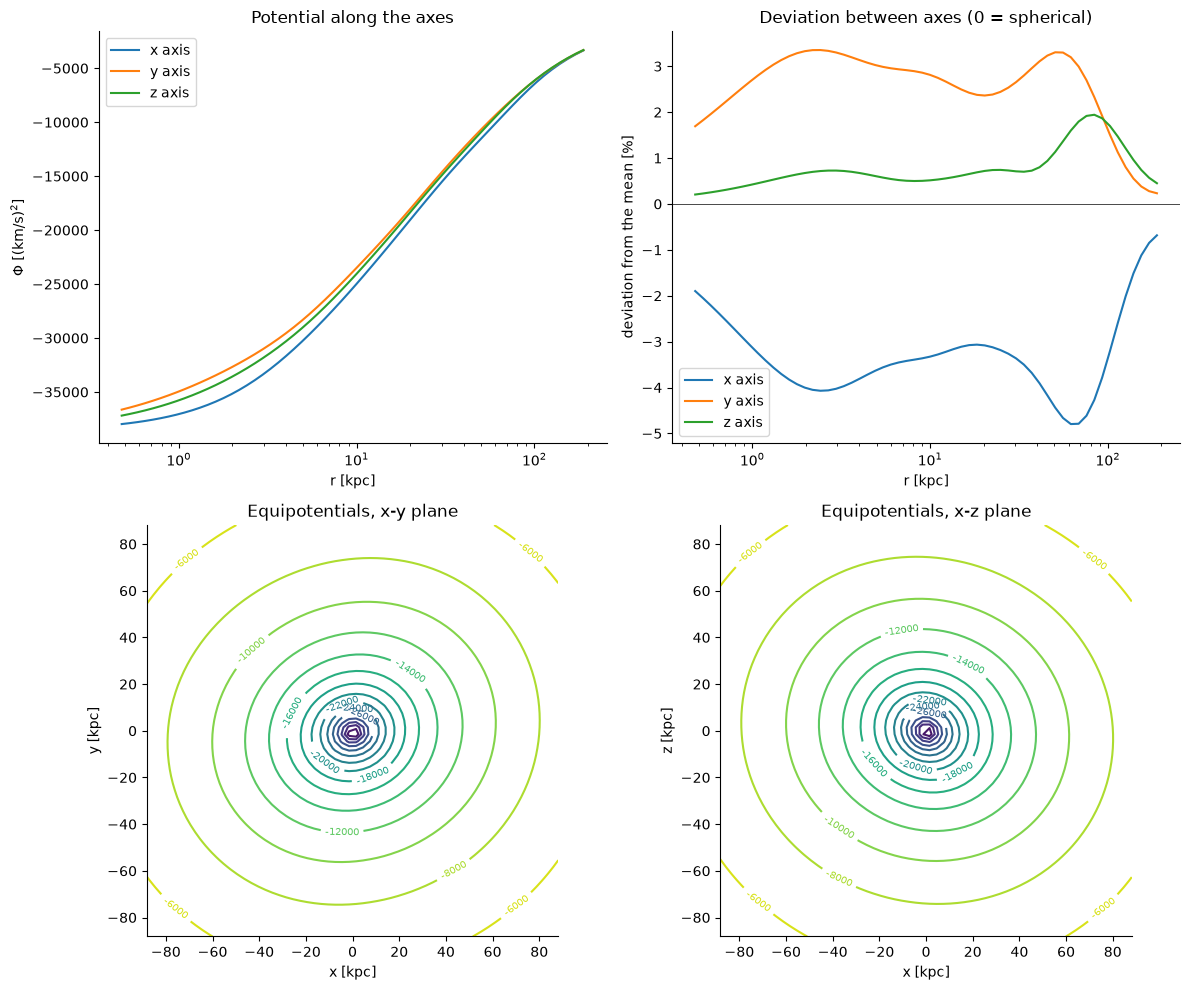

In [14]:
def build_SCF(file, N=10, L=4, plot=True):
    """
    Builds a galpy SCF (basis-function expansion) potential directly from the DM particles,
    with no spherical symmetry assumption, and optionally plots how spherical it is.

    N : number of radial terms
    L : number of angular terms (L = 0 is spherical)
    plot : whether to plot the potential along the axes and in two planes
    """
    ro, vo = 8.0, 220.0   # galpy's unit scales (kpc, km/s)

    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        m = np.full(len(pos), hdr["MassTable"][1])

    h = hdr.get("HubbleParam", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    M_unit = hdr.get("UnitMass_in_g", 1.989e43) * u.g / h

    pos = pos * L_unit.to(u.kpc)
    m = m * M_unit.to(u.Msun)

    # Center on the particles (all masses are equal)
    x = pos - pos.mean(axis=0)
    r_part = np.sort(np.linalg.norm(x.value, axis=1))      # sorted particle radii in kpc

    # Scale radius of the basis: the median radius works as a starting point
    a_phys = np.median(r_part) * u.kpc

    # SCF works in galpy natural units
    x_nat = conversion.parse_length(x, ro=ro, vo=vo)
    m_nat = conversion.parse_mass(m, ro=ro, vo=vo)
    a_nat = conversion.parse_length(a_phys, ro=ro, vo=vo)

    # Expansion coefficients from the particles; pos must have shape (3, N_particles)
    Acos, Asin = scf_compute_coeffs_nbody(x_nat.T, N, L, mass=m_nat, a=a_nat)
    pot_scf = SCFPotential(Acos=Acos, Asin=Asin, a=a_nat, ro=ro, vo=vo)
    # Added this before the loop as well, now you can get it without having to plot everything
    r_ax = np.geomspace(r_part[100], r_part[-1], 60) * u.kpc
    if plot:
        pot_unit = u.km**2 / u.s**2

        # --- Potential along the three coordinate axes ---
        # Radii from the 100th particle (as before, inside that it's noise) to the outermost one
        r_ax = np.geomspace(r_part[100], r_part[-1], 60) * u.kpc
        tiny = 1e-6 * r_ax            # galpy works in cylindrical coords, so the z axis needs R ~ 0
        zero = 0. * u.kpc

        Phi_x = evaluatePotentials(pot_scf, r_ax, zero, phi=0. * u.rad, quantity=True).to(pot_unit)
        Phi_y = evaluatePotentials(pot_scf, r_ax, zero, phi=90. * u.deg, quantity=True).to(pot_unit)
        Phi_z = evaluatePotentials(pot_scf, tiny, r_ax, phi=0. * u.rad, quantity=True).to(pot_unit)

        Phi_axes = {"x axis": Phi_x, "y axis": Phi_y, "z axis": Phi_z}
        Phi_mean = (Phi_x + Phi_y + Phi_z) / 3

        # --- Potential on a grid in the x-y and x-z planes ---
        lim = np.percentile(r_part, 90)                  # plot out to the 90th percentile radius
        g = np.linspace(-lim, lim, 60)                   # even number of points, so r = 0 is not on the grid
        X, Y = np.meshgrid(g, g)

        # x-y plane (z = 0): R = sqrt(x^2 + y^2), phi = arctan2(y, x)
        R_xy = np.hypot(X, Y).ravel() * u.kpc
        phi_xy = np.arctan2(Y, X).ravel() * u.rad
        Phi_xy = evaluatePotentials(pot_scf, R_xy, zero, phi=phi_xy, quantity=True)
        Phi_xy = Phi_xy.to_value(pot_unit).reshape(X.shape)

        # x-z plane (y = 0): R = |x|, phi = 0 for x > 0 and pi for x < 0, z = second axis
        R_xz = np.abs(X).ravel() * u.kpc
        phi_xz = np.where(X.ravel() >= 0, 0., np.pi) * u.rad
        Phi_xz = evaluatePotentials(pot_scf, R_xz, Y.ravel() * u.kpc, phi=phi_xz, quantity=True)
        Phi_xz = Phi_xz.to_value(pot_unit).reshape(X.shape)

        fig, ax = plt.subplots(2, 2, figsize=(12, 10))

        # Top left: the potential along each axis
        for name, Phi in Phi_axes.items():
            ax[0, 0].semilogx(r_ax.value, Phi.value, label=name)
        ax[0, 0].set(xlabel="r [kpc]", ylabel=r"$\Phi$ [(km/s)$^2$]", title="Potential along the axes")
        ax[0, 0].legend()

        # Top right: deviation of each axis from the mean of the three, in percent
        for name, Phi in Phi_axes.items():
            ax[0, 1].semilogx(r_ax.value, ((Phi - Phi_mean) / np.abs(Phi_mean)).decompose().value * 100,
                              label=name)
        ax[0, 1].axhline(0, color="k", lw=0.5)
        ax[0, 1].set(xlabel="r [kpc]", ylabel="deviation from the mean [%]",
                     title="Deviation between axes (0 = spherical)")
        ax[0, 1].legend()

        # Bottom row: equipotential contours; circles mean spherical
        for a, Phi_map, title, ylab in [(ax[1, 0], Phi_xy, "x-y plane", "y [kpc]"),
                                        (ax[1, 1], Phi_xz, "x-z plane", "z [kpc]")]:
            cs = a.contour(g, g, Phi_map, levels=15)
            a.clabel(cs, fontsize=7, fmt="%.0f")
            a.set(xlabel="x [kpc]", ylabel=ylab, title=f"Equipotentials, {title}", aspect="equal")

        plt.tight_layout()
        plt.show()

    return pot_scf, r_ax

pot_scf, r_ax = build_SCF("cutout_188106.hdf5", N=10, L=4)

/tmp/ipykernel_1683/3730333320.py:130: RuntimeWarning: invalid value encountered in log10
  cf = a.contourf(g, g, np.log10(rho_map), levels=20)



RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

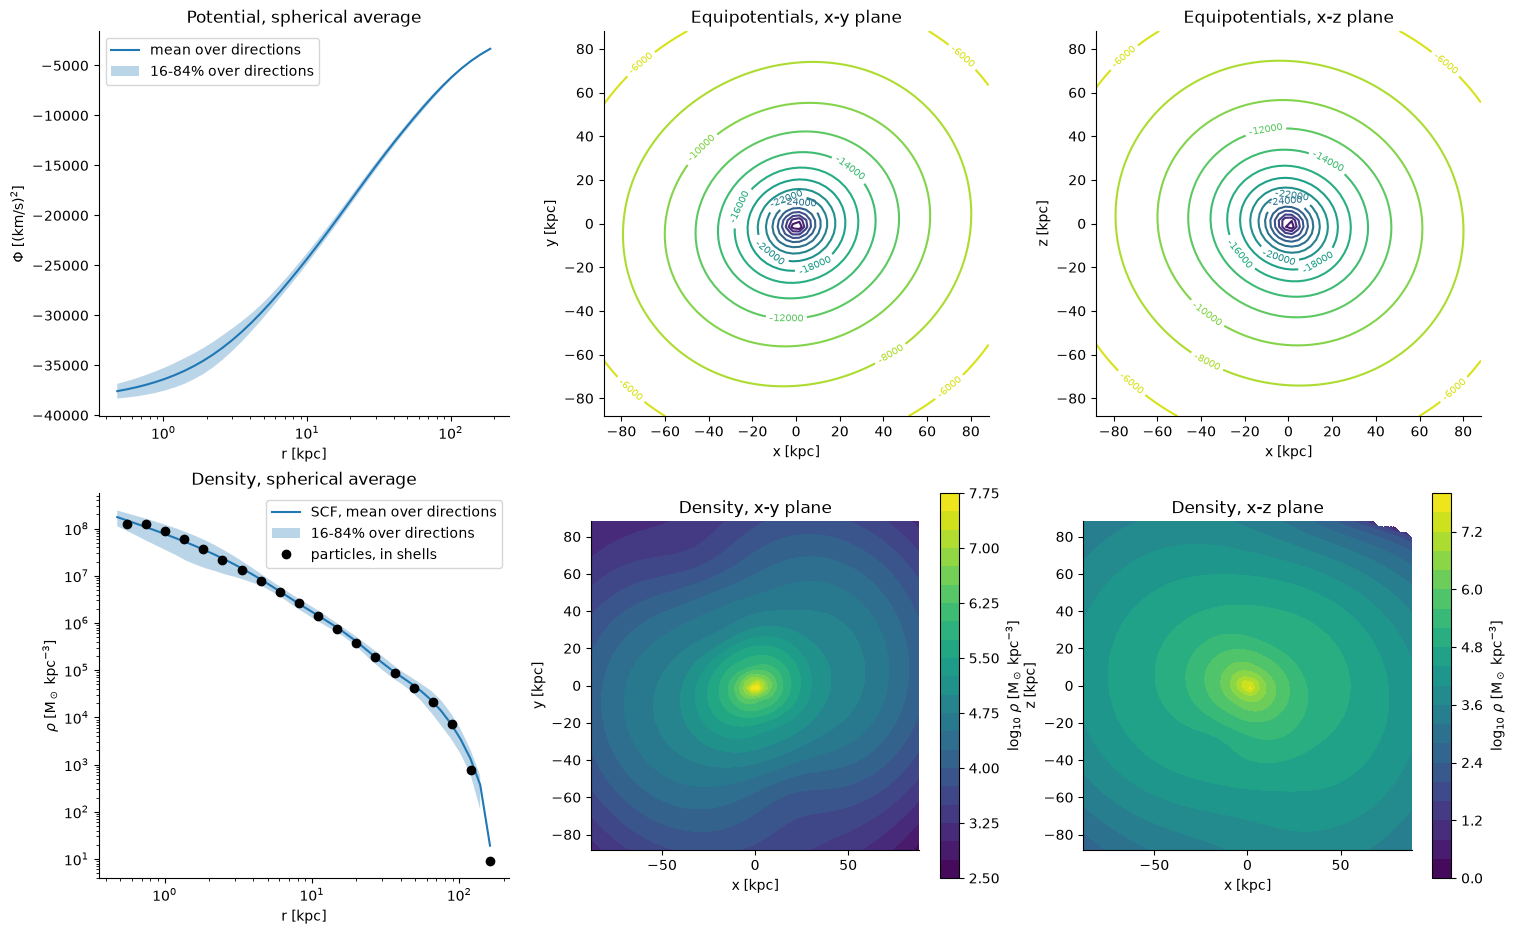

In [4]:
def plot_scf_potential_density(pot_scf, file, n_r=40, n_dir=200, n_shells=20, plot=True):
    """
    Plots the potential and the density of an SCF potential: spherically averaged profiles as a
    function of r, and maps in the x-y and x-z planes. The density measured directly from the
    particles in logarithmic shells is overlaid on the averaged density profile.

    Parameters:

    pot_scf : galpy.potential
              The SCF potential, e.g. from build_SCF

    file : .hdf5 file
           Data from the TNG simulation (one halo), the same file that was used for pot_scf

    n_r : int
          Number of radii for the spherical averages

    n_dir : int
            Number of directions, spread evenly over the sphere, to average over at each radius

    n_shells : int
               Number of logarithmic shells for the density measured from the particles

    plot : bool
           Whether to plot

    Returns:

    r_grid : astropy Quantity
             Radii (kpc) of the averaged profiles

    Phi_mean : astropy Quantity
               Potential (km^2/s^2) averaged over all directions

    rho_mean : astropy Quantity
               Density (Msun/kpc^3) averaged over all directions

    """
    pot_unit = u.km**2 / u.s**2
    rho_unit = u.Msun / u.kpc**3

    # Particle positions and mass, with the same conventions and centering as build_SCF
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
    h = hdr.get("HubbleParam", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    M_unit = hdr.get("UnitMass_in_g", 1.989e43) * u.g / h

    pos = pos * L_unit.to(u.kpc)
    m_part = (hdr["MassTable"][1] * M_unit.to(u.Msun)).value      # mass of one particle, Msun
    x = (pos - pos.mean(axis=0)).value
    r_part = np.sort(np.linalg.norm(x, axis=1))                    # sorted particle radii, kpc

    # --- Spherical averages: many directions at each radius ---
    r_grid = np.geomspace(r_part[100], r_part[-1], n_r)

    # Directions spread evenly over the sphere (Fibonacci spiral)
    i = np.arange(n_dir) + 0.5
    cos_t = 1 - 2 * i / n_dir
    sin_t = np.sqrt(1 - cos_t**2)
    phi_dir = np.pi * (1 + np.sqrt(5)) * i

    # Cylindrical coordinates of every (radius, direction) pair, shape (n_r, n_dir)
    R = (r_grid[:, None] * sin_t[None, :]).ravel() * u.kpc
    z = (r_grid[:, None] * cos_t[None, :]).ravel() * u.kpc
    phi = np.tile(phi_dir, n_r) * u.rad

    Phi_all = evaluatePotentials(pot_scf, R, z, phi=phi, quantity=True).to_value(pot_unit).reshape(n_r, n_dir)
    rho_all = evaluateDensities(pot_scf, R, z, phi=phi, quantity=True).to_value(rho_unit).reshape(n_r, n_dir)

    Phi_mean = Phi_all.mean(axis=1) * pot_unit
    rho_mean = rho_all.mean(axis=1) * rho_unit

    if plot:
        # --- Maps in the x-y and x-z planes ---
        lim = np.percentile(r_part, 90)
        g = np.linspace(-lim, lim, 60)       # even number of points, so r = 0 is not on the grid
        X, Y = np.meshgrid(g, g)

        # x-y plane (z = 0): R = sqrt(x^2 + y^2), phi = arctan2(y, x)
        R_xy = np.hypot(X, Y).ravel() * u.kpc
        z_xy = np.zeros(X.size) * u.kpc
        phi_xy = np.arctan2(Y, X).ravel() * u.rad

        # x-z plane (y = 0): R = |x|, phi = 0 for x > 0 and pi for x < 0, z = second axis
        R_xz = np.abs(X).ravel() * u.kpc
        z_xz = Y.ravel() * u.kpc
        phi_xz = np.where(X.ravel() >= 0, 0., np.pi) * u.rad

        maps = {}
        for name, (Rm, zm, pm) in {"x-y": (R_xy, z_xy, phi_xy), "x-z": (R_xz, z_xz, phi_xz)}.items():
            maps[name] = (
                evaluatePotentials(pot_scf, Rm, zm, phi=pm, quantity=True).to_value(pot_unit).reshape(X.shape),
                evaluateDensities(pot_scf, Rm, zm, phi=pm, quantity=True).to_value(rho_unit).reshape(X.shape))

        # --- Density measured directly from the particles, in logarithmic shells ---
        edges = np.geomspace(r_part[100], r_part[-1], n_shells + 1)
        counts, _ = np.histogram(r_part, bins=edges)
        rho_part = counts * m_part / (4 / 3 * np.pi * (edges[1:]**3 - edges[:-1]**3))
        r_shell = np.sqrt(edges[1:] * edges[:-1])

        fig, ax = plt.subplots(2, 3, figsize=(18, 11))

        # Row 1, column 1: potential averaged over all directions, with the 16-84 percentile range
        lo, hi = np.percentile(Phi_all, [16, 84], axis=1)
        ax[0, 0].semilogx(r_grid, Phi_mean.value, label="mean over directions")
        ax[0, 0].fill_between(r_grid, lo, hi, alpha=0.3, label="16-84% over directions")
        ax[0, 0].set(xlabel="r [kpc]", ylabel=r"$\Phi$ [(km/s)$^2$]", title="Potential, spherical average")
        ax[0, 0].legend()

        # Row 1, columns 2-3: equipotentials
        for a, name, ylab in [(ax[0, 1], "x-y", "y [kpc]"), (ax[0, 2], "x-z", "z [kpc]")]:
            cs = a.contour(g, g, maps[name][0], levels=15)
            a.clabel(cs, fontsize=7, fmt="%.0f")
            a.set(xlabel="x [kpc]", ylabel=ylab, title=f"Equipotentials, {name} plane", aspect="equal")

        # Row 2, column 1: density averaged over all directions, with the particle density
        lo, hi = np.percentile(rho_all, [16, 84], axis=1)
        ax[1, 0].loglog(r_grid, np.where(rho_mean.value > 0, rho_mean.value, np.nan), label="SCF, mean over directions")
        ax[1, 0].fill_between(r_grid, np.where(lo > 0, lo, np.nan), np.where(hi > 0, hi, np.nan),
                              alpha=0.3, label="16-84% over directions")
        ax[1, 0].loglog(r_shell, rho_part, "ko", label="particles, in shells")
        ax[1, 0].set(xlabel="r [kpc]", ylabel=r"$\rho$ [M$_\odot$ kpc$^{-3}$]", title="Density, spherical average")
        ax[1, 0].legend()

        # Row 2, columns 2-3: density maps on a log scale (non-positive values are masked)
        for a, name, ylab in [(ax[1, 1], "x-y", "y [kpc]"), (ax[1, 2], "x-z", "z [kpc]")]:
            rho_map = np.ma.masked_less_equal(maps[name][1], 0)
            cf = a.contourf(g, g, np.log10(rho_map), levels=20)
            fig.colorbar(cf, ax=a, label=r"log$_{10}$ $\rho$ [M$_\odot$ kpc$^{-3}$]")
            a.set(xlabel="x [kpc]", ylabel=ylab, title=f"Density, {name} plane", aspect="equal")

        plt.tight_layout()
        plt.show()

    return r_grid * u.kpc, Phi_mean, rho_mean

r_grid, Phi_mean, rho_mean = plot_scf_potential_density(pot_scf, "cutout_188106.hdf5")

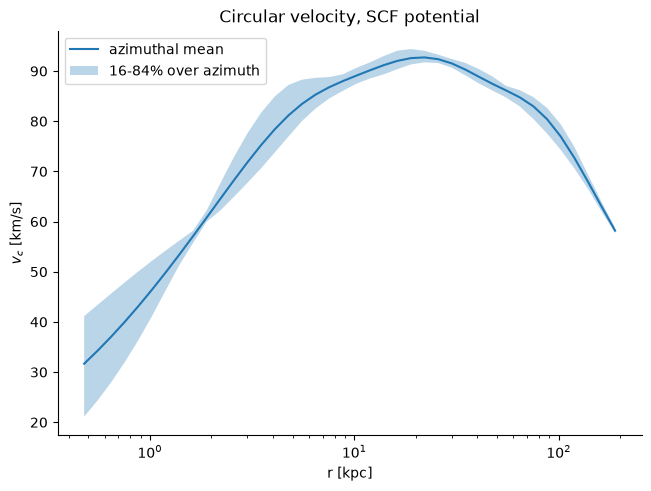

In [5]:
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from galpy.potential import vcirc

def circular_velocity_scf(pot_scf, r, n_phi=8, plot=True):
    """
    Computes the circular velocity v_c(r) of an SCF potential with galpy's vcirc, in the z = 0 plane.
    The SCF potential is not axisymmetric, so v_c depends on the azimuth. It is computed at 'n_phi'
    azimuths and averaged.

    Parameters:

    pot_scf : galpy.potential
              The SCF potential, e.g. from build_SCF

    r : astropy Quantity
        Radii (kpc) at which to evaluate v_c, within the range covered by the particles

    n_phi : int
            Number of azimuths (evenly spaced between 0 and 2 pi) to average over

    plot : bool
           Whether to plot v_c as a function of r

    Returns:

    vc : astropy Quantity
         The azimuthally averaged circular velocity (km/s) at the radii in 'r'

    """
    phis = np.linspace(0., 2 * np.pi, n_phi, endpoint=False) * u.rad

    # Circular velocity at every azimuth, shape (n_phi, len(r))
    vc_phi = np.array([vcirc(pot_scf, r, phi=phi, quantity=True).to_value(u.km / u.s) for phi in phis])

    vc = vc_phi.mean(axis=0) * u.km / u.s

    if plot:
        plt.semilogx(r.to_value(u.kpc), vc.value, label="azimuthal mean")
        # Spread between azimuths: it shows the asymmetry of the potential in the plane
        lo, hi = np.percentile(vc_phi, [16, 84], axis=0)
        plt.fill_between(r.to_value(u.kpc), lo, hi, alpha=0.3, label="16-84% over azimuth")
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$v_c$ [km/s]")
        plt.title("Circular velocity, SCF potential")
        plt.legend()
        plt.show()

    return vc

# For example on the radii of the averaged profiles from plot_scf_potential_density
r_grid, Phi_mean, rho_mean = plot_scf_potential_density(pot_scf, "cutout_188106.hdf5", plot=False)
vc_scf = circular_velocity_scf(pot_scf, r_grid)

/tmp/ipykernel_1683/2128826666.py:82: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



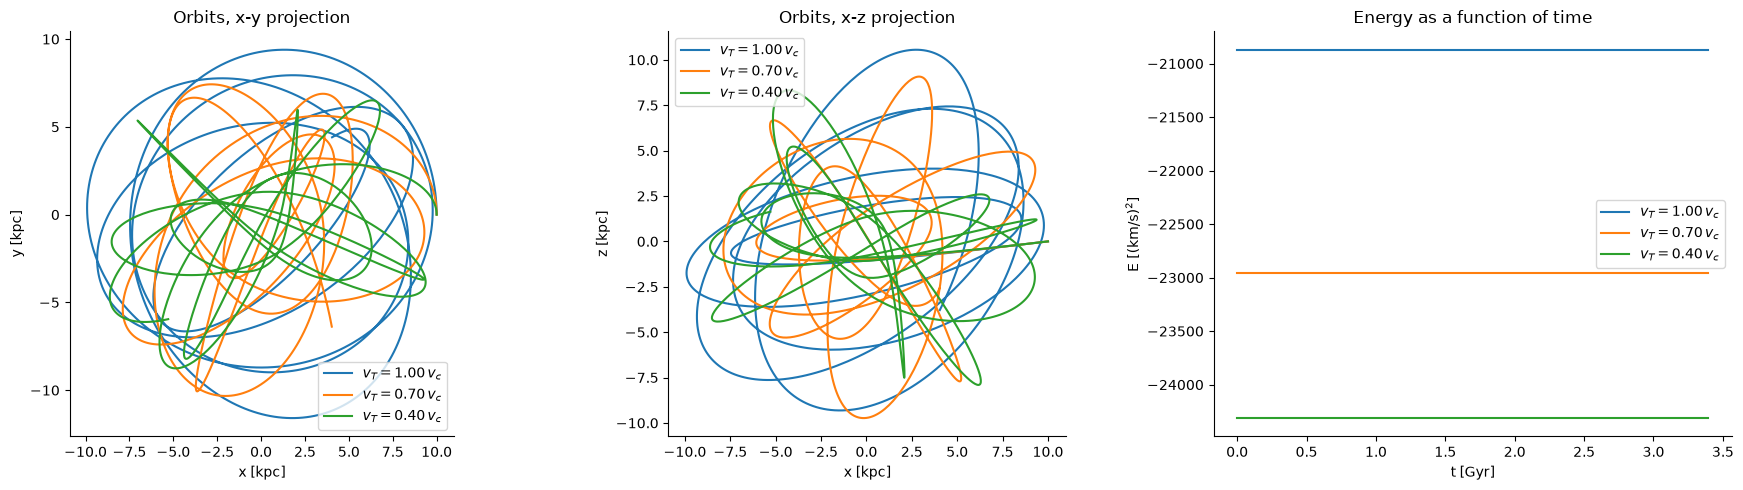

In [6]:
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from galpy.orbit import Orbit
from galpy.potential import vcirc

def integrate_orbits(pot, r0, f_vc=(1.0, 0.7, 0.4), n_orbits=5, n_steps=1000,
                     ro=8.0, vo=220.0, plot=True):
    """
    Integrates orbits in a galpy potential, spherical or not, and optionally plots them together with
    their energy. Every orbit starts at radius r0 on the x axis in the z = 0 plane (phi = 0), with a
    purely tangential velocity f * v_c(r0).

    Parameters:

    pot : galpy.potential
          The potential, e.g. pot_scf from build_SCF or pot_einasto from build_Einasto

    r0 : astropy Quantity
         Starting radius (kpc), should be inside the range covered by the particles.

    f_vc : sequence of float
           Tangential velocity of each orbit as a fraction of the circular velocity at r0 (at phi = 0).
           1.0 is a circular orbit in the plane. Smaller values give more eccentric orbits.

    n_orbits : float
               Integration time in units of the circular orbital period at r0

    n_steps : int
              Number of time steps

    ro, vo : float
             galpy's unit scales (kpc, km/s), must be the same as used for the potential

    plot : bool
           Whether to plot the orbits and their energy

    Returns:

    orbits : list of galpy.orbit.Orbit
             The integrated orbits, one for each value in f_vc

    ts : list of astropy Quantity
         The times (Gyr) at which each orbit was integrated

    """
    # Circular velocity at the starting point (phi = 0), where all the orbits start
    vc0 = vcirc(pot, r0, phi=0. * u.rad, quantity=True).to(u.km / u.s)

    # Integrate for n_orbits circular periods at r0
    T = n_orbits * (2 * np.pi * r0 / vc0).to(u.Gyr)
    ts = np.linspace(0, T.to_value(u.Gyr), n_steps) * u.Gyr

    orbits = []
    for f in f_vc:
        # [R, vR, vT, z, vz, phi]: purely tangential velocity, starting in the z = 0 plane
        o = Orbit([r0, 0. * u.km / u.s, f * vc0, 0. * u.kpc, 0. * u.km / u.s, 0. * u.rad],
                  ro=ro, vo=vo)
        o.integrate(ts, pot)
        orbits.append(o)

    if plot:
        fig, ax = plt.subplots(1, 3, figsize=(18, 5))

        for f, o in zip(f_vc, orbits):
            x = o.x(ts, quantity=True).to_value(u.kpc)
            y = o.y(ts, quantity=True).to_value(u.kpc)
            z = o.z(ts, quantity=True).to_value(u.kpc)
            E = o.E(ts, quantity=True).to_value(u.km**2 / u.s**2)
            label = rf"$v_T = {f:.2f}\,v_c$"

            ax[0].plot(x, y, label=label)
            ax[1].plot(x, z, label=label)
            ax[2].plot(ts.to_value(u.Gyr), E, label=label)

        ax[0].set(xlabel="x [kpc]", ylabel="y [kpc]", title="Orbits, x-y projection", aspect="equal")
        ax[1].set(xlabel="x [kpc]", ylabel="z [kpc]", title="Orbits, x-z projection", aspect="equal")
        ax[2].set(xlabel="t [Gyr]", ylabel=r"E [(km/s)$^2$]", title="Energy as a function of time")
        for a in ax:
            a.legend()

        plt.tight_layout()
        plt.show()

    return orbits, [ts] * len(orbits)

orbits, ts = integrate_orbits(pot_scf, r0=10 * u.kpc)

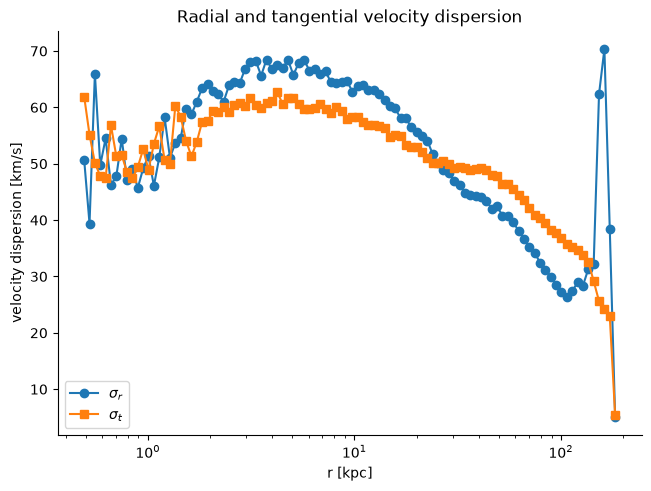

In [7]:
def velocity_dispersions(file, n_bins=20, plot=True, return_counts=False):
    """
    Measures the radial and tangential velocity dispersion of the DM particles as a function of
    radius, in logarithmic spherical shells around the center of the halo.

    The tangential dispersion is defined per component: sigma_t^2 = (sigma_theta^2 + sigma_phi^2) / 2,
    so that an isotropic halo has sigma_t = sigma_r.

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    n_bins : int
             Number of logarithmic radial shells

    plot : bool
           Whether to plot the dispersions as a function of r

    Returns:

    r_mid : astropy Quantity
            Geometric center of each shell (kpc)

    sigma_r : astropy Quantity
              Radial velocity dispersion (km/s) in each shell

    sigma_t : astropy Quantity
              Tangential velocity dispersion (km/s) per component, in each shell

    """
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        vel = f["PartType1/Velocities"][:]

    # Same unit conventions as before. TNG velocities are stored as v * sqrt(a), with a the scale
    # factor (a = 1 at z = 0)
    h = hdr.get("HubbleParam", 1.0)
    a = hdr.get("Time", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    v_unit = hdr.get("UnitVelocity_in_cm_per_s", 1e5) * u.cm / u.s

    pos = pos * L_unit.to(u.kpc)
    vel = vel * np.sqrt(a) * v_unit.to(u.km / u.s)

    # Positions relative to the center, velocities relative to the bulk velocity of the halo
    # (all particles have the same mass)
    x = (pos - pos.mean(axis=0)).value
    v = (vel - vel.mean(axis=0)).value

    r = np.linalg.norm(x, axis=1)
    theta = np.arccos(x[:, 2] / r)
    phi = np.arctan2(x[:, 1], x[:, 0])

    # Spherical unit vectors at the position of each particle
    e_r = x / r[:, None]
    e_th = np.column_stack([np.cos(theta) * np.cos(phi), np.cos(theta) * np.sin(phi), -np.sin(theta)])
    e_ph = np.column_stack([-np.sin(phi), np.cos(phi), np.zeros_like(phi)])

    # Velocity components in spherical coordinates
    v_r = np.sum(v * e_r, axis=1)
    v_th = np.sum(v * e_th, axis=1)
    v_ph = np.sum(v * e_ph, axis=1)

    # Logarithmic shells, from the 100th particle (as before, inside that it is noise) to the outermost
    edges = np.geomspace(np.sort(r)[100], r.max(), n_bins + 1)
    shell = np.digitize(r, edges) - 1

    counts = np.zeros(n_bins, dtype=int)
    sigma_r = np.full(n_bins, np.nan)
    sigma_t = np.full(n_bins, np.nan)
    for i in range(n_bins):
        sel = shell == i
        counts[i] = sel.sum()
        if sel.sum() < 2:
            continue
        # The standard deviation within a shell removes any mean streaming motion of the shell
        sigma_r[i] = v_r[sel].std()
        sigma_t[i] = np.sqrt((v_th[sel].var() + v_ph[sel].var()) / 2)

    r_mid = np.sqrt(edges[1:] * edges[:-1]) * u.kpc
    sigma_r = sigma_r * u.km / u.s
    sigma_t = sigma_t * u.km / u.s

    if plot:
        plt.semilogx(r_mid.to_value(u.kpc), sigma_r.to_value(u.km / u.s), "o-", label=r"$\sigma_r$")
        plt.semilogx(r_mid.to_value(u.kpc), sigma_t.to_value(u.km / u.s), "s-", label=r"$\sigma_t$")
        plt.xlabel("r [kpc]")
        plt.ylabel("velocity dispersion [km/s]")
        plt.title("Radial and tangential velocity dispersion")
        plt.legend()
        plt.show()

    if return_counts:
        return r_mid, sigma_r, sigma_t, edges * u.kpc, counts
    return r_mid, sigma_r, sigma_t

r_mid, sigma_r, sigma_t = velocity_dispersions("cutout_188106.hdf5", n_bins=100)

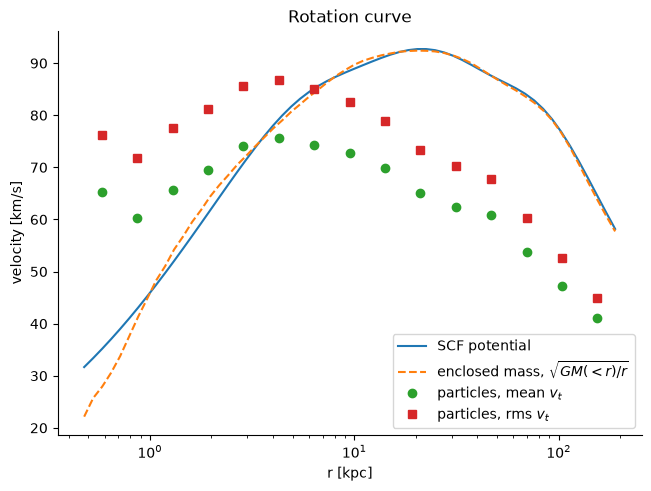

In [15]:
import h5py
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from astropy.constants import G

def tangential_velocity(file, r_grid, n_bins=15):
    """
    Measures the full tangential velocity v_t of the DM particles as a function of radius, in
    logarithmic spherical shells that cover the range of 'r_grid'. v_t is the speed perpendicular to
    the radial direction, v_t = sqrt(v_theta^2 + v_phi^2) = sqrt(|v|^2 - v_r^2).

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    r_grid : astropy Quantity
             Radii (kpc) of the SCF grid. Only its range is used, for the outer and inner shell edges.

    n_bins : int
             Number of logarithmic radial shells

    Returns:

    r_mid : astropy Quantity
            Geometric center of each shell (kpc)

    vt_mean : astropy Quantity
              Mean tangential speed v_t in each shell (km/s)

    vt_rms : astropy Quantity
             Root-mean-square tangential speed in each shell (km/s), sqrt(<v_t^2>)

    """
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        vel = f["PartType1/Velocities"][:]

    # Same unit conventions as before. TNG velocities are stored as v * sqrt(a), with a the scale
    # factor (a = 1 at z = 0)
    h = hdr.get("HubbleParam", 1.0)
    a = hdr.get("Time", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    v_unit = hdr.get("UnitVelocity_in_cm_per_s", 1e5) * u.cm / u.s

    pos = pos * L_unit.to(u.kpc)
    vel = vel * np.sqrt(a) * v_unit.to(u.km / u.s)

    # Positions relative to the center (the same center as in build_SCF), velocities relative to the
    # bulk velocity of the halo (all particles have the same mass)
    x = (pos - pos.mean(axis=0)).value
    v = (vel - vel.mean(axis=0)).value
    r = np.linalg.norm(x, axis=1)

    # Radial velocity: the projection of the velocity onto the radial direction
    e_r = x / r[:, None]
    v_r = np.sum(v * e_r, axis=1)

    # What remains of the speed after removing the radial part is perpendicular to the radius
    # (the maximum guards against tiny negative values from rounding errors)
    v_t = np.sqrt(np.maximum(np.sum(v**2, axis=1) - v_r**2, 0.))

    # Logarithmic shells over the range of the SCF grid
    edges = np.geomspace(r_grid.to_value(u.kpc).min(), r_grid.to_value(u.kpc).max(), n_bins + 1)
    shell = np.digitize(r, edges) - 1

    vt_mean = np.full(n_bins, np.nan)
    vt_rms = np.full(n_bins, np.nan)
    for i in range(n_bins):
        sel = shell == i
        if sel.sum() < 2:
            continue
        vt_mean[i] = v_t[sel].mean()
        vt_rms[i] = np.sqrt(np.mean(v_t[sel]**2))

    r_mid = np.sqrt(edges[1:] * edges[:-1]) * u.kpc
    return r_mid, vt_mean * u.km / u.s, vt_rms * u.km / u.s


def compare_rotation_curves(file, n_bins=15, plot=True):
    """
    Plots the circular velocity v_c(r) of the halo from the SCF potential and from the enclosed mass,
    together with the tangential velocity v_t of the particles.

    1) directly from the SCF potential, with vcirc in the z = 0 plane averaged over azimuth
    2) from the enclosed mass of the particles, v_c = sqrt(G M(<r) / r)
    3) the tangential velocity v_t of the particles (the speed perpendicular to the radial direction)

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    n_bins : int
             Number of logarithmic radial shells for the particle velocities

    plot : bool
           Whether to plot the curves

    Returns:

    (r_ax, vc_model) : radii and circular velocity from the SCF potential
    (r_ax, vc_mass) : radii and circular velocity from the enclosed mass
    (r_t, vt_mean, vt_rms) : shell centers, mean v_t and rms v_t of the particles
    all as astropy Quantities (kpc and km/s)

    """
    # 1) Directly from the SCF potential, on the radius grid that build_SCF returns
    pot_scf, r_ax = build_SCF(file, plot=False)
    vc_model = circular_velocity_scf(pot_scf, r_ax, plot=False)

    # 2) From the enclosed mass: v_c = sqrt(G M(<r) / r). The enclosed mass is the fourth output of
    # potential_plotter, which is interpolated onto the SCF radius grid (both span the same range)
    _, r_M, _, M = potential_plotter(file, plot_potential=False, plot_density=False)
    M_ax = np.interp(r_ax, r_M, M)
    vc_mass = np.sqrt(G * M_ax / r_ax).to(u.km / u.s)

    # 3) The tangential velocities of the particles
    r_t, vt_mean, vt_rms = tangential_velocity(file, r_ax, n_bins=n_bins)

    if plot:
        plt.semilogx(r_ax.to_value(u.kpc), vc_model.to_value(u.km / u.s), label="SCF potential")
        plt.semilogx(r_ax.to_value(u.kpc), vc_mass.to_value(u.km / u.s), "--",
                     label=r"enclosed mass, $\sqrt{GM(<r)/r}$")
        plt.semilogx(r_t.to_value(u.kpc), vt_mean.to_value(u.km / u.s), "o",
                     label=r"particles, mean $v_t$")
        plt.semilogx(r_t.to_value(u.kpc), vt_rms.to_value(u.km / u.s), "s",
                     label=r"particles, rms $v_t$")
        plt.xlabel("r [kpc]")
        plt.ylabel("velocity [km/s]")
        plt.title("Rotation curve")
        plt.legend()
        plt.show()

    return (r_ax, vc_model), (r_ax, vc_mass), (r_t, vt_mean, vt_rms)

curve_scf, curve_mass, curve_t = compare_rotation_curves("cutout_188106.hdf5")